In [5]:
import pandas as pd
import matplotlib.pyplot as plt

def finish(filename):
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

In [6]:
subscribers   = pd.read_csv("clean_subscribers.csv", parse_dates=["signup_date", "churn_date"])
titles        = pd.read_csv("clean_titles.csv")
watch_history = pd.read_csv("clean_watch_history.csv", parse_dates=["watch_date"])
reviews       = pd.read_csv("clean_reviews.csv")
print("Loaded!")

Loaded!


In [7]:
wh = watch_history.merge(
    titles[["title_id", "primary_genre", "type", "country", "language", "is_original"]],
    on="title_id", how="left")

wh["watch_hours"] = wh["watch_duration_min"] / 60
wh["month"] = wh["watch_date"].dt.to_period("M")
wh["year"]  = wh["watch_date"].dt.year
wh["month_num"] = wh["watch_date"].dt.month

wh.head()

,watch_id,subscriber_id,title_id,watch_date,device,region,content_duration_min,watch_duration_min,completion_pct,completed,primary_genre,type,country,language,is_original,watch_hours,month,year,month_num
0,1,SUB107630,TTL205207,2024-01-01,Smart TV,East Asia,888,826.7,93.1,True,Comedy,TV Show,Mexico,Spanish,True,13.778333,2024-01,2024,1
1,2,SUB114773,TTL204889,2025-10-18,Mobile,South Asia,2340,1866.4,79.8,False,Drama,TV Show,Indonesia,Indonesian,False,31.106667,2025-10,2025,10
2,3,SUB106013,TTL206882,2026-04-26,Mobile,Latin America,656,75.0,11.4,False,Comedy,TV Show,India,Hindi,True,1.250000,2026-04,2026,4
3,4,SUB100939,TTL208849,2026-03-09,Mobile,North America,500,493.2,98.6,True,Horror,TV Show,India,Hindi,True,8.220000,2026-03,2026,3
4,5,SUB107223,TTL202529,2023-12-27,Tablet,North America,141,94.6,67.1,False,Action,Movie,Japan,Japanese,False,1.576667,2023-12,2023,12


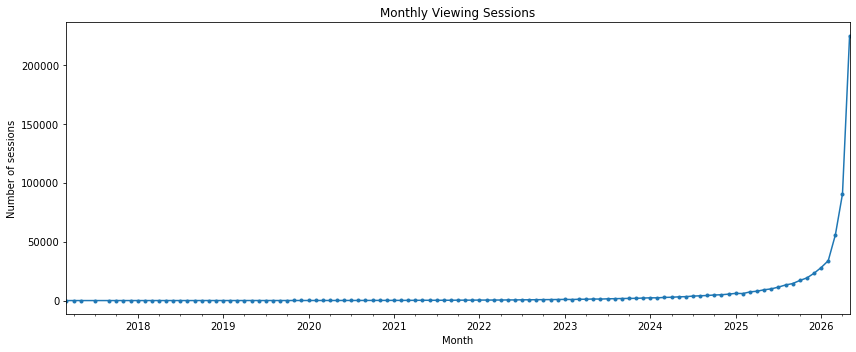

In [8]:
monthly = wh.groupby("month").size()
monthly.plot(figsize=(12, 5), marker="o", markersize=3)
plt.title("Monthly Viewing Sessions")
plt.xlabel("Month")
plt.ylabel("Number of sessions")
finish("chart01_monthly_sessions.png")

Every year is higher than the year before.
2026 is far above all other years: about 1.16 million hours in May alone.
2026 only has data up to May 


In [9]:
print(wh["watch_date"].max())

2026-05-31 00:00:00


Within 2025, hours rose steadily from January to December, so no clear seasonal dip.

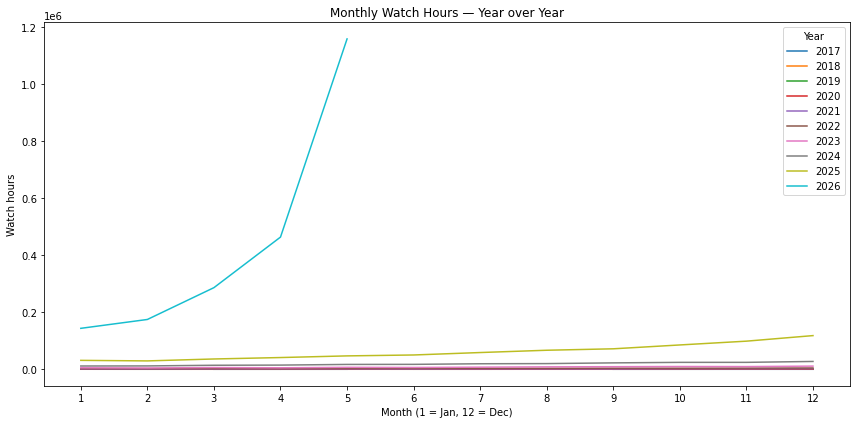

In [10]:
yoy = wh.pivot_table(index="month_num", columns="year",
                     values="watch_hours", aggfunc="sum")
yoy.plot(figsize=(12, 6))
plt.title("Monthly Watch Hours — Year over Year")
plt.xlabel("Month (1 = Jan, 12 = Dec)")
plt.ylabel("Watch hours")
plt.xticks(range(1, 13))
plt.legend(title="Year")
finish("chart02_watch_hours_yoy.png")

Viewing was very low and flat from 2017 to about 2023.
Growth sped up from 2024 and exploded in 2026.
The last month (around May 2026) has about 225,000 sessions, roughly a third of all 650,000 sessions in one month.
So what: the platform is growing very fast, but most of the data comes from recent months, so overall totals are dominated by 2026.

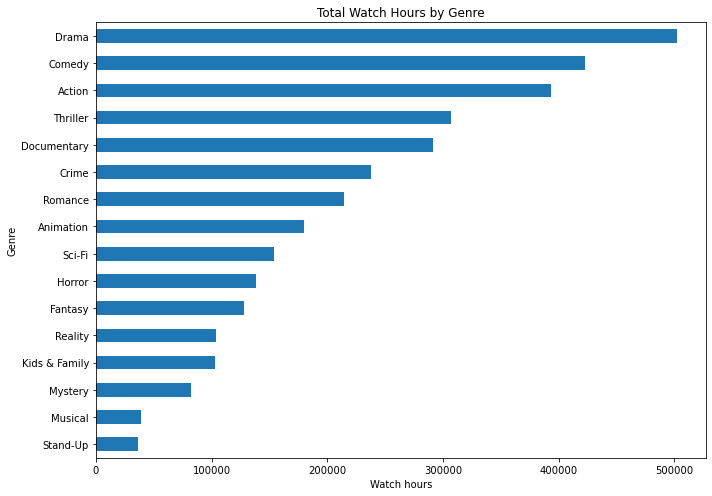

In [11]:
genre = wh.groupby("primary_genre")["watch_hours"].sum().sort_values()
genre.plot(kind="barh", figsize=(10, 7))
plt.title("Total Watch Hours by Genre")
plt.xlabel("Watch hours")
plt.ylabel("Genre")
finish("chart03_hours_by_genre.png")

Top 3: Drama (~500K hours), Comedy (~420K), Action (~390K).
Bottom 2: Stand-Up (~37K) and Musical (~39K).
Drama gets about 13 times more hours than Stand-Up.
So what: a few genres drive most viewing; check spending on low-hour genres.

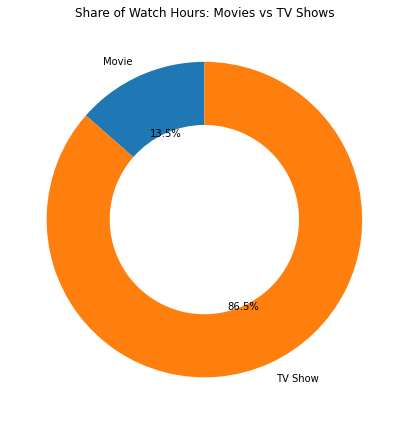

In [12]:
type_hours = wh.groupby("type")["watch_hours"].sum()
plt.figure(figsize=(6, 6))
plt.pie(type_hours, labels=type_hours.index, autopct="%1.1f%%",
        startangle=90, wedgeprops={"width": 0.4})
plt.title("Share of Watch Hours: Movies vs TV Shows")
finish("chart04_movies_vs_tv.png")

TV Shows: 86.5% of watch hours, Movies: 13.5%.
TV gets about 6 times more hours (partly because series have many episodes).
So what: series keep subscribers watching longer, which helps retention.

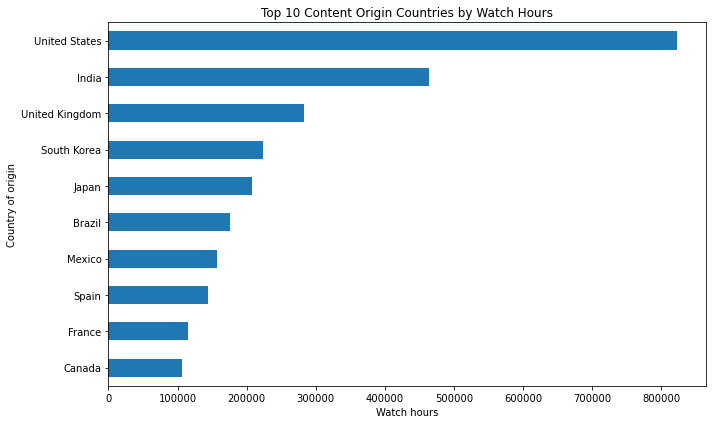

In [13]:
countries = wh.groupby("country")["watch_hours"].sum().nlargest(10).sort_values()
countries.plot(kind="barh", figsize=(10, 6))
plt.title("Top 10 Content Origin Countries by Watch Hours")
plt.xlabel("Watch hours")
plt.ylabel("Country of origin")
finish("chart05_top_countries.png")

United States leads (~820K hours), about double India (~460K).
Then UK (~280K), South Korea (~220K), Japan (~205K).
7 of the top 10 are non-English-speaking countries (India, Korea, Japan, Brazil, Mexico, Spain, France).
So what: strong demand for international content; India and Korea are big opportunities.

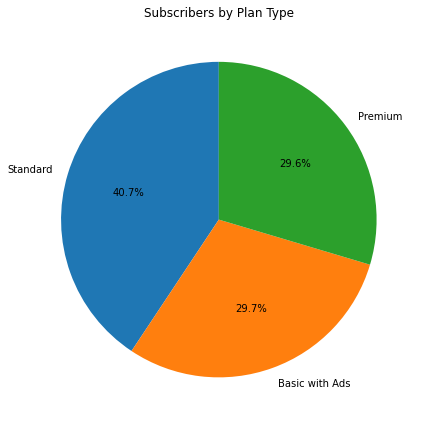

In [14]:
plans = subscribers["plan_type"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(plans, labels=plans.index, autopct="%1.1f%%", startangle=90)
plt.title("Subscribers by Plan Type")
finish("chart06_plan_distribution.png")

Standard is most popular (40.7%).
Basic with Ads (29.7%) and Premium (29.6%) are almost equal.
Interesting: the cheapest plan is not the most popular, and nearly 30% pay for Premium.
So what: customers are willing to pay more; there's room to move Basic users up.

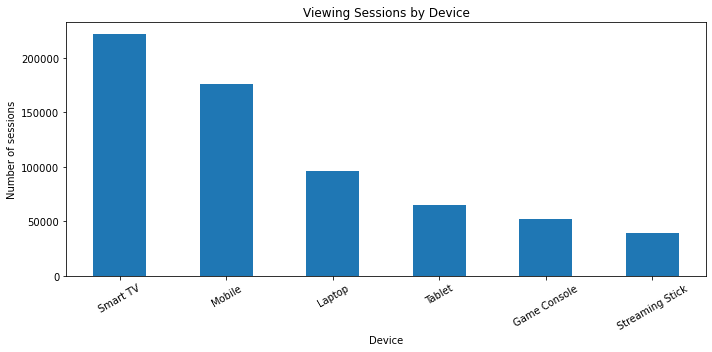

In [15]:
devices = wh["device"].value_counts()
devices.plot(kind="bar", figsize=(10, 5))
plt.title("Viewing Sessions by Device")
plt.xlabel("Device")
plt.ylabel("Number of sessions")
plt.xticks(rotation=30)
finish("chart07_devices.png")

Smart TV is #1 (~222K sessions, about 34%), then Mobile (~176K, about 27%).
TV + Mobile = about 61% of all sessions.
Streaming Stick is lowest (~39K, about 6%).
So what: the TV and mobile apps should get the most investment.

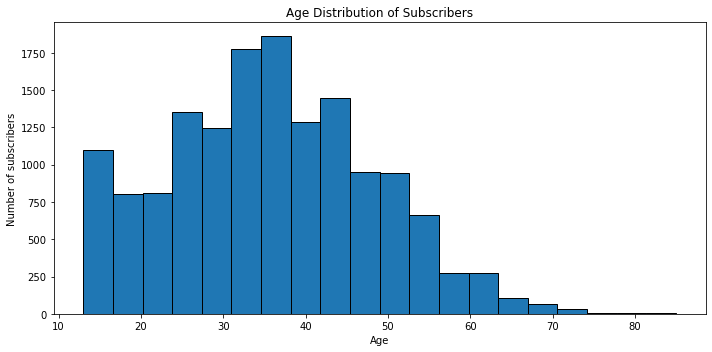

In [16]:
subscribers["age"].plot(kind="hist", bins=20, edgecolor="black", figsize=(10, 5))
plt.title("Age Distribution of Subscribers")
plt.xlabel("Age")
plt.ylabel("Number of subscribers")
finish("chart08_age_distribution.png")

Most subscribers are aged 25–50, with the peak around 30–40.
Very few over 60, and almost none over 70.
There are subscribers as young as 13, which is worth a note: account holders under 18 may be unusual.
So what: the core audience is adults in their 30s; older audiences are a growth gap.

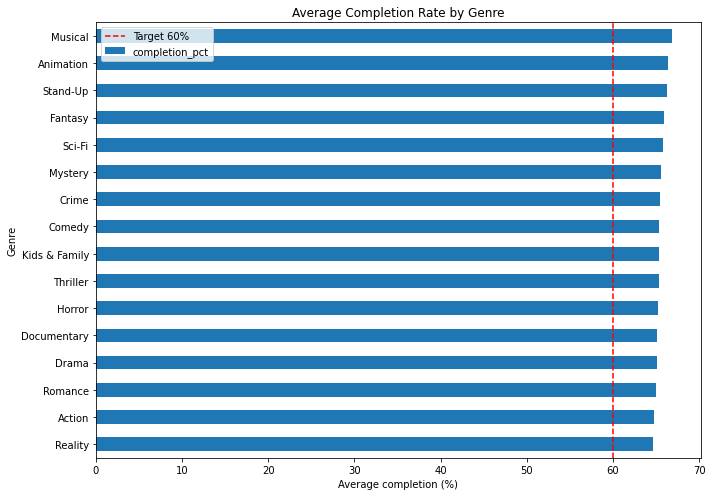

In [17]:
completion = wh.groupby("primary_genre")["completion_pct"].mean().sort_values()
completion.plot(kind="barh", figsize=(10, 7))
plt.axvline(60, color="red", linestyle="--", label="Target 60%")
plt.title("Average Completion Rate by Genre")
plt.xlabel("Average completion (%)")
plt.ylabel("Genre")
plt.legend()
finish("chart09_completion_by_genre.png")

All 16 genres are above the 60% target.
Range is very narrow: Reality ~64.5% (lowest) to Musical ~67% (highest).
Compare with Chart 3: Musical and Stand-Up are the least watched but the most completed. Drama and Action are most watched but slightly less completed.
So what: small genres satisfy the people who watch them; they may deserve more promotion.

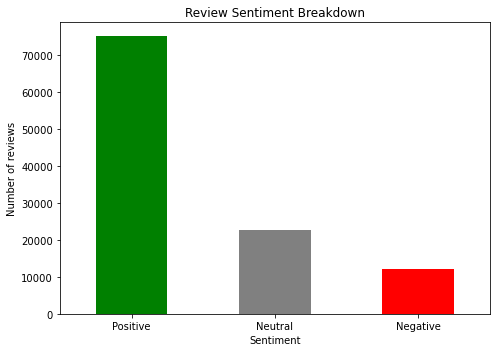

In [18]:
sentiment = reviews["sentiment"].value_counts()
sentiment.plot(kind="bar", figsize=(7, 5), color=["green", "grey", "red"])
plt.title("Review Sentiment Breakdown")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
finish("chart10_sentiment.png")

Positive: 75,007 (68.2%), Neutral: 22,759 (20.7%), Negative: 12,234 (11.1%).
Positive reviews are about 6 times more than negative.
So what: subscribers are mostly happy; negative reviews could identify weak titles.